# 03 · HMM Training

## Model definition

| HMM component | In this project |
|---|---|
| Hidden states $z_t$ | the 4 activities (state $k$ = `ACTIVITIES[k]`) |
| Observations $x_t$ | the 56-dim standardized feature vector of window $t$ |
| Start probabilities $\pi$ | $P(z_1 = k)$ |
| Transition matrix $A$ | $A_{ij} = P(z_{t+1}=j \mid z_t=i)$ |
| Emissions $B$ | $x_t \mid z_t=k \sim \mathcal{N}(\mu_k, \mathrm{diag}(\sigma_k^2))$ |

The model is implemented from scratch in `src/hmm.py`. The forward, backward and Viterbi
recursions all run in log space. A diagonal covariance is needed because there are only
about 460 training windows: a full 56×56 covariance per state would have about 1,600 parameters per
state.

## Which algorithms, and why

| Task | Algorithm | Why it fits our evaluation |
|---|---|---|
| Estimate $\pi, A, B$ | **Supervised MLE**, then **Baum-Welch** (EM) | Our training windows are labeled, so MLE gives a good start in one pass. Baum-Welch then refines the parameters by maximizing $P(X)$ and stops when the log-likelihood gain falls below `tol = 1e-4`. |
| Label each window | **Viterbi** | It returns the single most likely *sequence* of activities. Sensitivity, specificity and accuracy are scored per window against one label, so a single best path is exactly what the metrics need. |
| Likelihoods, EM statistics | **Forward-backward** | It gives $P(X)$ for the convergence check and the posteriors $\gamma, \xi$ that Baum-Welch needs. |

Viterbi (joint MAP) was preferred over per-window posterior decoding because it cannot produce
impossible one-window flickers between activities. That matters on the unseen test recordings,
where the activity changes during the recording.

In [1]:
# --- Environment setup (works locally and in Google Colab) ---
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/Orrie-Dan/Human-Activity-HMM.git"
    ROOT = Path("/content/human-activity-hmm")
    if not ROOT.exists():
        !git clone -q {REPO_URL} {ROOT}
    %cd {ROOT}
    !pip install -q -r requirements.txt
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# The recordings are in the repository (data/raw/, data/test/). Fallback only: if
# data/raw/ is empty in Colab, upload a zip of its contents (p01_<activity>_<nn>/ + metadata.csv).
RAW = ROOT / "data" / "raw"
if IN_COLAB and not any(RAW.glob("p*_*_*")):
    import io, zipfile
    from google.colab import files
    for name, content in files.upload().items():
        zipfile.ZipFile(io.BytesIO(content)).extractall(RAW)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import apply_style

apply_style()
pd.set_option("display.precision", 3)


In [3]:
from src.dataset import build_feature_table

if config.FEATURES_FILE.exists():
    table = pd.read_csv(config.FEATURES_FILE)
else:  # build it if notebook 02 has not been run
    table, _ = build_feature_table()
    config.FEATURES_FILE.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(config.FEATURES_FILE, index=False)
print(f"{len(table)} windows from {table['recording'].nunique()} recordings")


462 windows from 65 recordings


## Parameter initialization

We first estimate every parameter **from the labels** (maximum likelihood):

- $\mu_k, \sigma_k^2$: mean and variance of the windows of activity $k$ (variance floored at
  1e-3).
- $\pi$, $A$: counts of first states and transitions, plus a **pseudocount of 1**.

The pseudocount matters. Each recording contains a single activity, so the data only shows
self-transitions. Without smoothing, $A$ would be the identity matrix and the model could never
switch activity.

start probabilities: {'standing': 0.246, 'walking': 0.261, 'jumping': 0.203, 'still': 0.29}


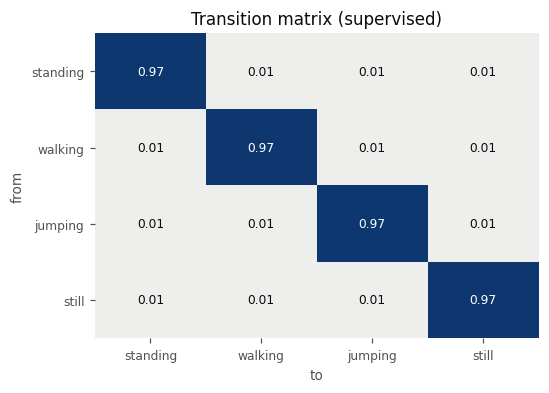

In [4]:
from src.training import train_model
from src.visualization import plot_matrix

supervised = train_model(table, baum_welch=False)
A = pd.DataFrame(supervised.hmm.transmat, index=config.ACTIVITIES, columns=config.ACTIVITIES)
plot_matrix(A, "Transition matrix (supervised)", vmin=0, vmax=1,
            xlabel="to", ylabel="from");
print("start probabilities:", {a: round(float(p), 3) for a, p in zip(config.ACTIVITIES, supervised.hmm.startprob)})

Emission means of a few key features per state (in standardized units, so 0 = the average over all training windows):

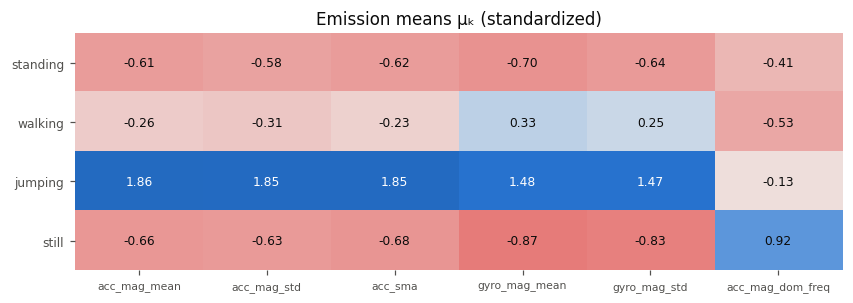

In [5]:
from src.visualization import DIVERGING_CMAP

key = ["acc_mag_mean", "acc_mag_std", "acc_sma", "gyro_mag_mean", "gyro_mag_std", "acc_mag_dom_freq"]
idx = [supervised.feature_columns.index(f) for f in key]
means = pd.DataFrame(supervised.hmm.means[:, idx], index=config.ACTIVITIES, columns=key)
fig, ax = plt.subplots(figsize=(9, 2.8))
plot_matrix(means, "Emission means μₖ (standardized)", cmap=DIVERGING_CMAP, vmin=-2.5, vmax=2.5, ax=ax)
ax.tick_params(axis="x", labelsize=7);

**Emission probabilities.** Each state's emission is a 56-dimensional Gaussian, which cannot be
drawn directly. Because the covariance is diagonal, it factorizes into one 1-D Gaussian per feature,
$p(x \mid z=k) = \prod_f \mathcal{N}(x_f;\, \mu_{kf}, \sigma^2_{kf})$. Below are those 1-D densities
for six key features.

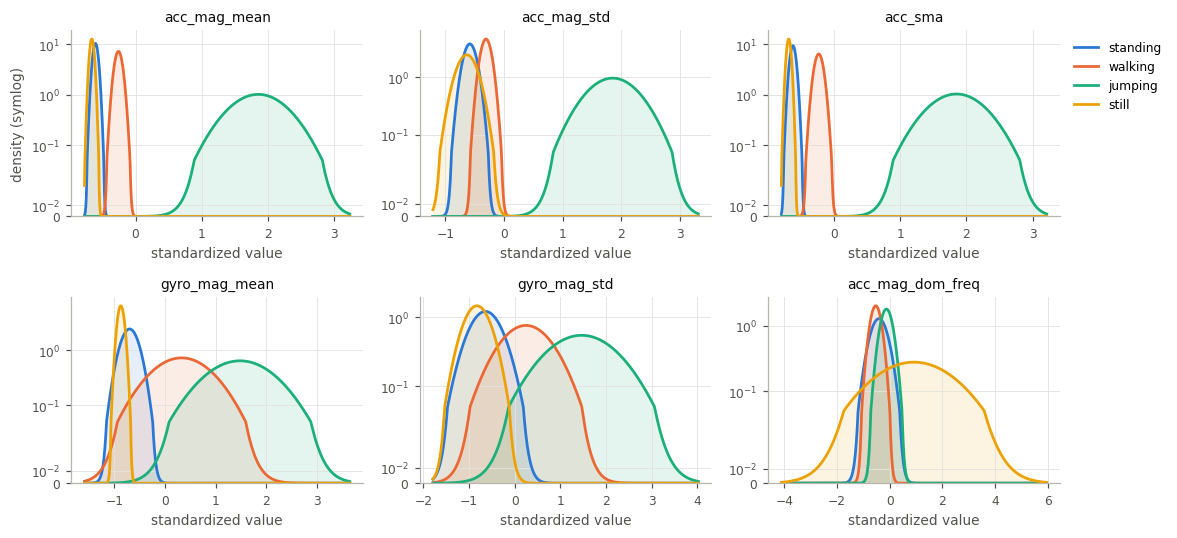

In [6]:
from src.visualization import plot_emissions

plot_emissions(supervised.hmm.means, supervised.hmm.variances, supervised.feature_columns, key);

- **Jumping** is far from all other states in the acceleration features (about 2 standard
  deviations above the mean, with a wide spread). One acceleration feature alone identifies it.
- **Walking** sits between: clearly above standing and still in acceleration, and overlapping
  jumping only in the gyroscope features.
- **Standing vs still** overlap in `acc_mag_mean` and `acc_mag_std` but separate in
  `gyro_mag_mean`: still has a very narrow peak (no rotation at all), while hand tremor
  rotates the phone slightly.
- `acc_mag_dom_freq` is very broad for still. When the phone does not move, the "dominant
  frequency" is just the strongest noise bin, anywhere up to 25 Hz. It is informative only for
  the moving activities.

## Training (Baum-Welch)

Starting from the supervised parameters, Baum-Welch (EM) re-estimates $\pi$, $A$, $\mu$ and
$\sigma^2$ **without using the labels**. It runs forward-backward to get the state posteriors
$\gamma_t(k)$ and the transition posteriors $\xi_t(i,j)$, then updates the parameters as
weighted averages. The training log-likelihood is guaranteed not to decrease.

5 iterations, log-likelihood 122 -> 7660


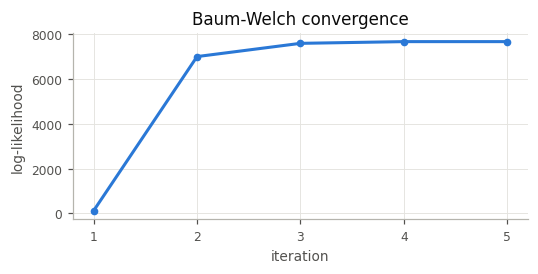

In [7]:
from src.visualization import plot_history

refined = train_model(table, baum_welch=True)
plot_history(refined.baum_welch_history);
print(f"{len(refined.baum_welch_history)} iterations, "
      f"log-likelihood {refined.baum_welch_history[0]:.0f} -> {refined.baum_welch_history[-1]:.0f}")

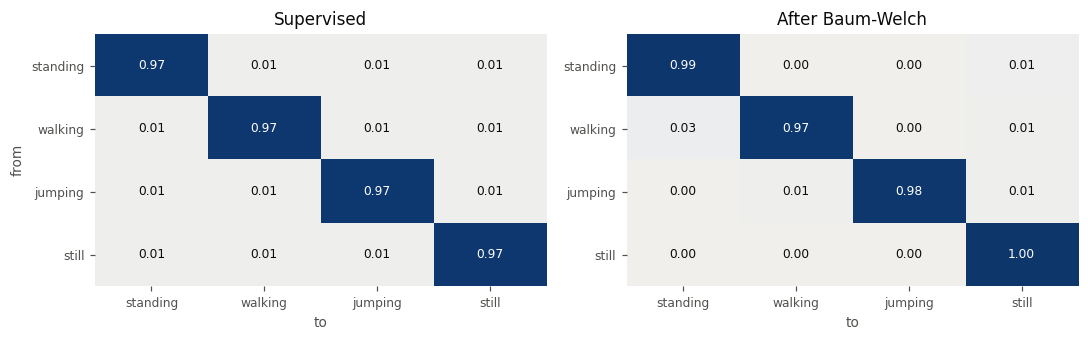

In [8]:
A_bw = pd.DataFrame(refined.hmm.transmat, index=config.ACTIVITIES, columns=config.ACTIVITIES)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
plot_matrix(A, "Supervised", vmin=0, vmax=1, ax=axes[0], xlabel="to", ylabel="from")
plot_matrix(A_bw, "After Baum-Welch", vmin=0, vmax=1, ax=axes[1], xlabel="to")
fig.tight_layout()

Baum-Welch replaces the uniform pseudocount switches with what it infers from the data. Most
switches drop to about 0, and still becomes absorbing (1.00). A few stay above 0, such as
walking → standing (0.03) and standing → still (0.01). EM reassigns some windows *inside* a recording to
another state (for example, the handling at the start of the still recordings), and those
reassignments look like switches. So these probabilities describe artifacts in our recordings,
not real changes of activity. We come back to this in notebook 04.

State $k$ is assumed to stay matched to activity $k$ after EM. This holds because EM starts
from the supervised parameters, and we check it empirically through the evaluation in
notebook 04.

## Decoding (Viterbi)

The most likely state path for one (training) recording:

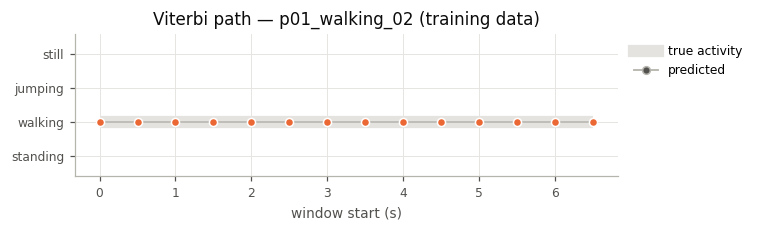

In [9]:
from src.training import predict
from src.visualization import plot_decoded

seq = table[table["recording"] == "p01_walking_02"].sort_values("window_index")
plot_decoded(seq["window_start_s"], seq["activity"], predict(refined, seq).loc[seq.index],
             "Viterbi path — p01_walking_02 (training data)")
plt.gcf().tight_layout()